<a href="https://colab.research.google.com/github/dsumathiphd/TYL-Agentic-AI/blob/main/Multi_Agent_Framework_AutoGen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
grpcio-status 1.85.1 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-datastore 2.27.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
proto-plus 1.29.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorflow 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 5.29.6 which is incompatible.
google-cloud-storage-control 1.17.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
googleapis-common-proto

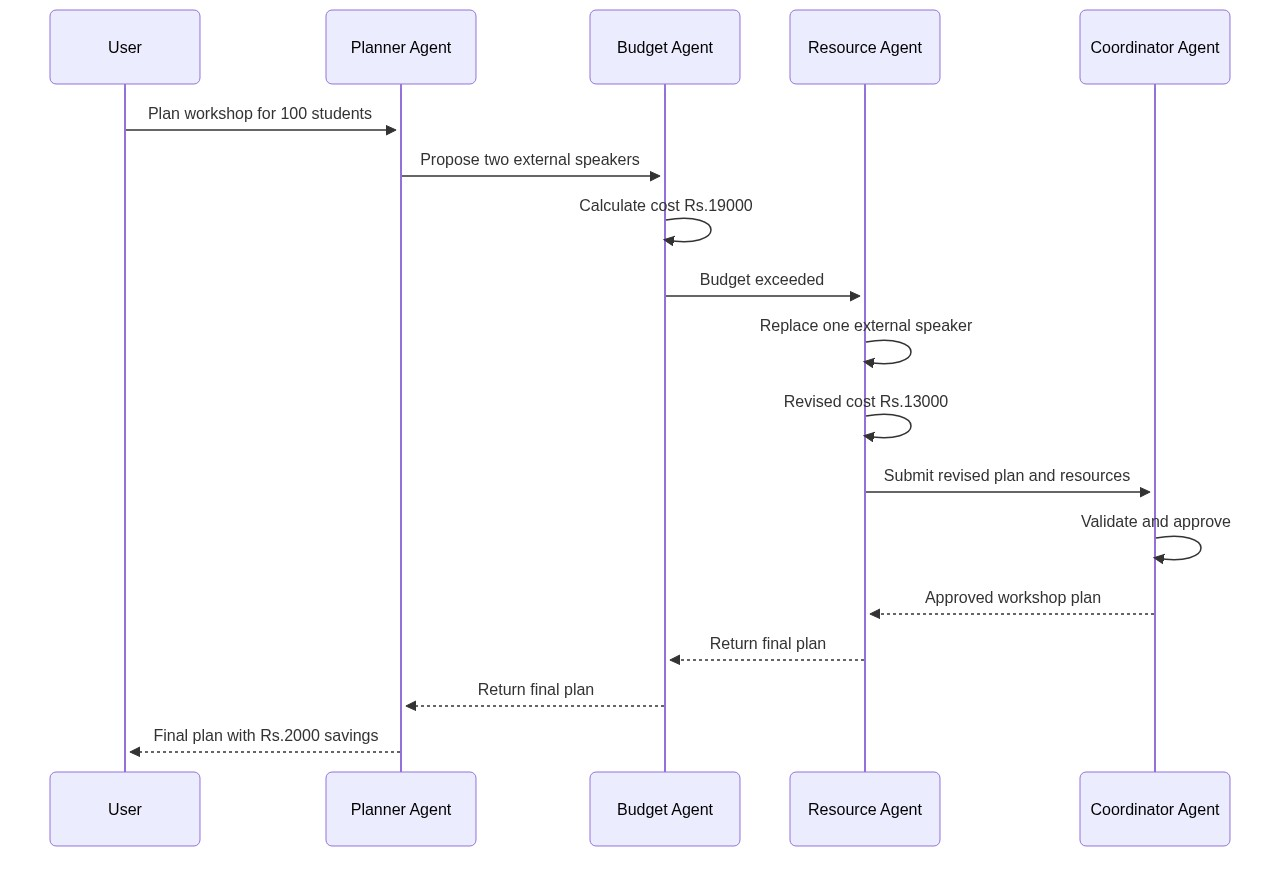

In [ ]:
# =====================================================
# AUTOGEN - MULTI-AGENT WORKSHOP PLANNING SYSTEM
# Google Colab | No API Key | No Ollama | No Paid Credits
# Rule-based conversational agents - No LLM required
# =====================================================

# Step 1: Install AutoGen

%pip install -q autogen-core


# Step 2: Import required libraries

from dataclasses import dataclass

from autogen_core import (
    AgentId,
    MessageContext,
    RoutedAgent,
    SingleThreadedAgentRuntime,
    message_handler
)
#agents are represented as Python classes derived from RoutedAgent.
#------------------------------------------

# Step 3: Define message structure

@dataclass
class WorkshopMessage:

    students: int = 100
    budget: int = 15000
    external_speakers: int = 2
    internal_speakers: int = 0
    total_cost: int = 0
    agenda: str = ""
    resources: str = ""
    status: str = "PENDING"
#The WorkshopMessage class defines the information exchanged between agents.
#The @dataclass decorator automatically generates methods
#such as the constructor, making it easier to create and manage structured messages.
#-----------------------------------------------------

# Step 4: Create Planner Agent

class PlannerAgent(RoutedAgent): #RoutedAgent is the base class provided by AutoGen Core.

    def __init__(self):
        super().__init__("Workshop Planner")

    @message_handler
    async def handle_message(
        self,
        message: WorkshopMessage,
        ctx: MessageContext
    ) -> WorkshopMessage:

        print("\nPlanner Agent:")
        print("Planning workshop for", message.students, "students")
        print("Initially proposing two external speakers")

        message.agenda = (
            "Introduction, AI Demo, Hands-on Lab"
        )

        return await self.send_message(
            message,
            AgentId("budget", "default")
        )
#RoutedAgent is the base class provided by AutoGen Core.
#By inheriting this class, the Planner Agent obtains the framework's capabilities for receiving, processing and sending messages.
#------------------------------------------------

# Step 5: Create Budget Agent

class BudgetAgent(RoutedAgent):

    def __init__(self):
        super().__init__("Budget Manager")   #Agent Initialization

    @message_handler
    async def handle_message(
        self,
        message: WorkshopMessage,
        ctx: MessageContext
    ) -> WorkshopMessage:

        message.total_cost = (
            message.external_speakers * 6000
            + 5000
            + 2000
        )

        print("\nBudget Agent:")
        print("Estimated cost: Rs.", message.total_cost)
        print("Maximum budget: Rs.", message.budget)

        if message.total_cost > message.budget:
            print("Budget exceeded. Requesting revision.")
        else:
            print("Budget is within the limit.")

        return await self.send_message(
            message,
            AgentId("resource", "default")
        )


# Step 6: Create Resource Agent

class ResourceAgent(RoutedAgent):

    def __init__(self):
        super().__init__("Resource Manager")

    @message_handler
    async def handle_message(
        self,
        message: WorkshopMessage,
        ctx: MessageContext
    ) -> WorkshopMessage:

        print("\nResource Agent:")

        # Revise the plan until it meets the budget

        while (
            message.total_cost > message.budget
            and message.external_speakers > 0
        ):

            message.external_speakers -= 1
            message.internal_speakers += 1

            message.total_cost = (
                message.external_speakers * 6000
                + 5000
                + 2000
            )

            print("Replacing external speaker with internal faculty")
            print("Revised cost: Rs.", message.total_cost)

        message.resources = (
            "Seminar Hall, Projector, Computer Laboratory"
        )

        print("College facilities allocated")

        return await self.send_message(
            message,
            AgentId("coordinator", "default")
        )


# Step 7: Create Coordinator Agent

class CoordinatorAgent(RoutedAgent):

    def __init__(self):
        super().__init__("Workshop Coordinator")

    @message_handler
    async def handle_message(
        self,
        message: WorkshopMessage,
        ctx: MessageContext
    ) -> WorkshopMessage:

        print("\nCoordinator Agent:")

        if message.total_cost <= message.budget:

            message.status = "APPROVED"
            print("Workshop plan approved")

        else:

            message.status = "NOT APPROVED"
            print("Insufficient budget")

        return message


# Step 8: Create AutoGen runtime

runtime = SingleThreadedAgentRuntime()


# Step 9: Register all four agents

await PlannerAgent.register(
    runtime,
    "planner",
    lambda: PlannerAgent()
)

await BudgetAgent.register(
    runtime,
    "budget",
    lambda: BudgetAgent()
)

await ResourceAgent.register(
    runtime,
    "resource",
    lambda: ResourceAgent()
)

await CoordinatorAgent.register(
    runtime,
    "coordinator",
    lambda: CoordinatorAgent()
)


# Step 10: Start the runtime

runtime.start()


# Step 11: Define workshop requirements

initial_message = WorkshopMessage(
    students=100,
    budget=15000
)


# Step 12: Execute multi-agent communication

try:

    result = await runtime.send_message(
        initial_message,
        AgentId("planner", "default")
    )

finally:

    await runtime.stop_when_idle()


# Step 13: Display final workshop plan

print("\n" + "=" * 50)
print("           FINAL WORKSHOP PLAN")
print("=" * 50)

print("Workshop          : Agentic AI")
print("Duration          : One Day")
print("Students          :", result.students)
print("Agenda            :", result.agenda)
print("External Speakers :", result.external_speakers)
print("Internal Faculty  :", result.internal_speakers)
print("Resources         :", result.resources)
print("Maximum Budget    : Rs.", result.budget)
print("Total Expenditure : Rs.", result.total_cost)
print("Remaining Budget  : Rs.",
      result.budget - result.total_cost)
print("Status            :", result.status)

print("=" * 50)


# Step 14: Validate the results

assert result.total_cost == 13000
assert result.external_speakers == 1
assert result.internal_speakers == 1
assert result.budget - result.total_cost == 2000
assert result.status == "APPROVED"
assert result.total_cost <= result.budget

print("\nAll validation tests passed successfully!")


# Step 15: Create Mermaid sequence diagram

mermaid_code = """
sequenceDiagram
    participant U as User
    participant P as Planner Agent
    participant B as Budget Agent
    participant R as Resource Agent
    participant C as Coordinator Agent

    U->>P: Plan workshop for 100 students
    P->>B: Propose two external speakers
    B->>B: Calculate cost Rs.19000
    B->>R: Budget exceeded
    R->>R: Replace one external speaker
    R->>R: Revised cost Rs.13000
    R->>C: Submit revised plan and resources
    C->>C: Validate and approve
    C-->>R: Approved workshop plan
    R-->>B: Return final plan
    B-->>P: Return final plan
    P-->>U: Final plan with Rs.2000 savings
"""

print("\nMERMAID DIAGRAM SOURCE:\n")
print(mermaid_code)


# Step 16: Display Mermaid diagram

import base64
import json
import requests

from IPython.display import Image, display

diagram_data = {
    "code": mermaid_code,
    "mermaid": {"theme": "default"}
}

encoded = base64.urlsafe_b64encode(
    json.dumps(diagram_data).encode("utf-8")
).decode("ascii")

url = "https://mermaid.ink/img/" + encoded

try:

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    if not response.headers.get(
        "Content-Type", ""
    ).startswith("image/"):

        raise ValueError("Invalid image response")

    display(Image(data=response.content))

except Exception as e:

    print("Mermaid rendering unavailable:", str(e))
    print("Copy the Mermaid source into https://mermaid.live/")


# =====================================================
# KEY CONCEPTS:
#
# RoutedAgent  : Creates individual agents
# AgentId      : Identifies each agent
# WorkshopMessage : Information exchanged between agents
# message_handler : Receives and processes messages
# send_message : Enables agent-to-agent communication
# Runtime      : Manages agent execution
#
# This program uses the actual AutoGen Core framework
# with rule-based agents rather than LLM-based agents.
#
# No API key, local model, GPU or Ollama is required.
# Internet access is needed for package installation
# and optional Mermaid image rendering.
#
# Verification:
# Independent end-to-end Colab execution is unverified.
# The assertions validate results during execution.
# =====================================================